# What does the NequIP scaler do?

Investigation of `NequIP_experiments/test.ipynb` and experiment 11. All diagnostic heads were fitted on **800 training structures (115,200 atoms)** and assessed on **50 validation structures (7,200 atoms)**. The held-out test set was not accessed. Original models, configurations and notebook are unchanged.

The last cell in `test.ipynb` assigns the frozen model's scaler to `c` but prints `b`, so its displayed frozen-model numbers actually belong to experiment 07. The corrected expressions are `c.per_element_scaling[14]` and `c.per_element_scaling[8]`.

## Exact forward calculation

For atom $i$, the frozen backbone produces 128 scalar features $h_i$. The model predicts

$$\hat\sigma_i = b_{Z_i} + s_{Z_i}\,L_w(h_i).$$

Here $L_w$ is the e3nn linear readout (including its fixed normalization convention), $s_Z$ is one learned multiplicative scale per element, and $b_Z$ is one learned additive offset per element. The readout has 128 shared weights and no internal bias. There are two active scales and two active offsets for Si/O: 132 trainable scalar parameters in total.

The scaler acts **after the readout**. It does not standardize the hidden features, change the geometry, divide the training targets, clip predictions or impose a bound. The scale is an unconstrained parameter and can become negative. A common rescaling $s_Z\mapsto a s_Z$, $w\mapsto w/a$ leaves predictions unchanged. The individual parameter magnitudes therefore do not measure prediction quality by themselves.

The energy model uses the analogous local-energy calculation, followed by summation over atoms to obtain total energy. Its scale belongs to an energy-target parameterization; the shielding scale belongs to a shielding-target parameterization. Copying the energy scale is not required when the readout is replaced.

## Initialization and loss

The custom NMR pre-fit initializes each element offset from its training-label mean and the scale from its training-label population standard deviation, with the small ridge denominator and variance floor used in the code. These are **initial values**, not fixed normalization constants. Both then train on the raw shielding MSE in ppm² (multiplied by the configured common loss weight 1000). This does not equalize O and Si errors: there are twice as many O atoms and their target spread is larger.

The energy scaler's pre-fit estimates per-element contributions to energy variance from total structure energies; it is not the same statistical calculation as directly observing each atom's shielding. Neither model's learned scales should be compared as if they were a universal unit conversion.


In [1]:
from pathlib import Path
import json
import pandas as pd
OUT = Path('/Users/louismcauliffe/.codex/.chatgpt-projects/g-p-6aa93f0341cc8191bbd47fb85a4101fb/scaler-investigation')
scales = pd.read_csv(OUT / 'scales.csv')
metrics = pd.read_csv(OUT / 'metrics.csv')
diagnostics = json.loads((OUT / 'diagnostics.json').read_text())
print(scales.pivot(index='model', columns='element', values='scale').round(6).to_string())


element                O        Si
model                             
06-energy       1.307072  1.174986
07-scratch     19.110533  8.767133
09-finetuned   19.290968  8.875148
10-scratch     19.274637  8.756788
11-checkpoint  22.904581  4.736466
11-export      19.197689  8.789599
12-checkpoint  92.640472 -2.188244


## Distinguish the export from the trained checkpoint

Experiment 11's `model.pt` does not equal `checkpoints/best.ckpt` (epoch 300). The export retains the pre-fit scale/offset values; reconstructing the seeded fresh head gives readout weights within $9\times10^{-7}$ of the export. This strongly supports an effectively initial export. The training log records the export save before “Starting fit”, consistent with sanity validation; the custom exporter has no `trainer.sanity_checking` guard. The original run's exact sanity-check batch sequence has not been reproduced, so the historical mechanism remains an evidence-backed explanation rather than a complete replay.

All three frozen artifacts below (11 export, 11 checkpoint, 12 checkpoint) have embedding/interaction state exactly equal to the source energy checkpoint. Their predictions were recomputed and checked against the existing evaluation data. Experiment 09 and 10 comparisons use the existing, separately verified validation predictions.


In [2]:
print('Training-label statistics:')
print(pd.DataFrame(diagnostics['label_statistics']).T.rename(index={'8':'O','14':'Si'}).round(6).to_string())
print('\nValidation RMSE (ppm):')
print(metrics.query("split == 'valid'").pivot(index='model', columns='element', values='RMSE').round(4).to_string())


Training-label statistics:
          mean        std
O   201.527278  19.197690
Si  436.087223   8.789599

Validation RMSE (ppm):
element                                      All        O      Si
model                                                            
09 full fine-tuning                       1.7799   2.0930  0.8619
10 from scratch                           2.2385   2.5985  1.2361
11 checkpoint scales/offsets refit only  12.1483  13.4304  9.0550
11 export scales/offsets refit only      14.5107  16.5934  8.9996
11 exported model.pt                     16.9840  19.7963  9.0323
11 trained checkpoint                    12.4949  13.8336  9.2536
12 checkpoint scales/offsets refit only   7.8298   7.1701  9.0055
12 trained checkpoint                     7.8655   7.2264  9.0087
LS head; scales fixed to 1                5.6825   6.2267  4.3966
LS head; scales fixed to NMR std          5.7190   6.2170  4.5630
LS head; scales fixed to energy           5.6657   6.2115  4.3744
LS head; scal

## Controlled diagnostic fits

1. **Refit scales/offsets only:** keep the saved 128 readout weights fixed and fit a separate affine recalibration for each element on training predictions. Because all saved scales are nonzero, this is equivalent to optimizing only the two scales and two offsets.
2. **Refit the shared linear head with fixed scales:** solve least squares for the shared 128 weights and two elemental intercepts. Test training-label standard deviations, unit scales, energy scales, and the trained experiment-11 scales. These fixed choices constrain the relative elemental scaling differently.
3. **Refit the existing head class including scale ratio:** absorb the common scale into the weights, set O's scale to 1, and profile over the Si/O ratio. For each ratio, solve the remaining linear least-squares problem. Search both signs with log absolute ratio in [-8, 8], refine every grid-local minimum, and select using training error only. This is a strong numerical optimization diagnostic, not a formal global-optimality proof.
4. **Separate linear heads:** fit 128 independent weights plus an intercept for each element. This is a more flexible function class. Improvement here cannot be attributed solely to fixing the scaler or optimizer.

Feature centering and standardization use training statistics only and improve numerical conditioning. Free elemental intercepts preserve the original shared-head function class. Fits use float64 least squares (relative singular-value cutoff $10^{-10}$) without AdamW weight decay, so they diagnose attainable unregularized fits rather than replaying the original optimizer. No validation labels select coefficients or scale ratio. All results are exploratory validation results, not an independent test-set claim.


In [3]:
p = diagnostics['profiled_shared_head']
print('Fitted Si/O scale ratio:', p['ratio_Si_over_O'])
print('Training RMSE:', p['train_mse'] ** 0.5)
print('\nTrain and validation RMSE, all atoms:')
print(metrics.query("element == 'All'").pivot(index='model', columns='split', values='RMSE').round(4).to_string())


Fitted Si/O scale ratio: -0.676716886467537
Training RMSE: 5.05146924503248

Train and validation RMSE, all atoms:
split                                      train    valid
model                                                    
09 full fine-tuning                       0.6918   1.7799
10 from scratch                           1.2942   2.2385
11 checkpoint scales/offsets refit only  11.5129  12.1483
11 export scales/offsets refit only      13.6262  14.5107
11 exported model.pt                     15.5380  16.9840
11 trained checkpoint                    11.6932  12.4949
12 checkpoint scales/offsets refit only   7.5495   7.8298
12 trained checkpoint                     7.5591   7.8655
LS head; scales fixed to 1                5.3295   5.6825
LS head; scales fixed to NMR std          5.3175   5.7190
LS head; scales fixed to energy           5.3058   5.6657
LS head; scales fixed to exp11            5.6241   6.0477
LS separate head per element              4.4638   5.0077
LS shared head;

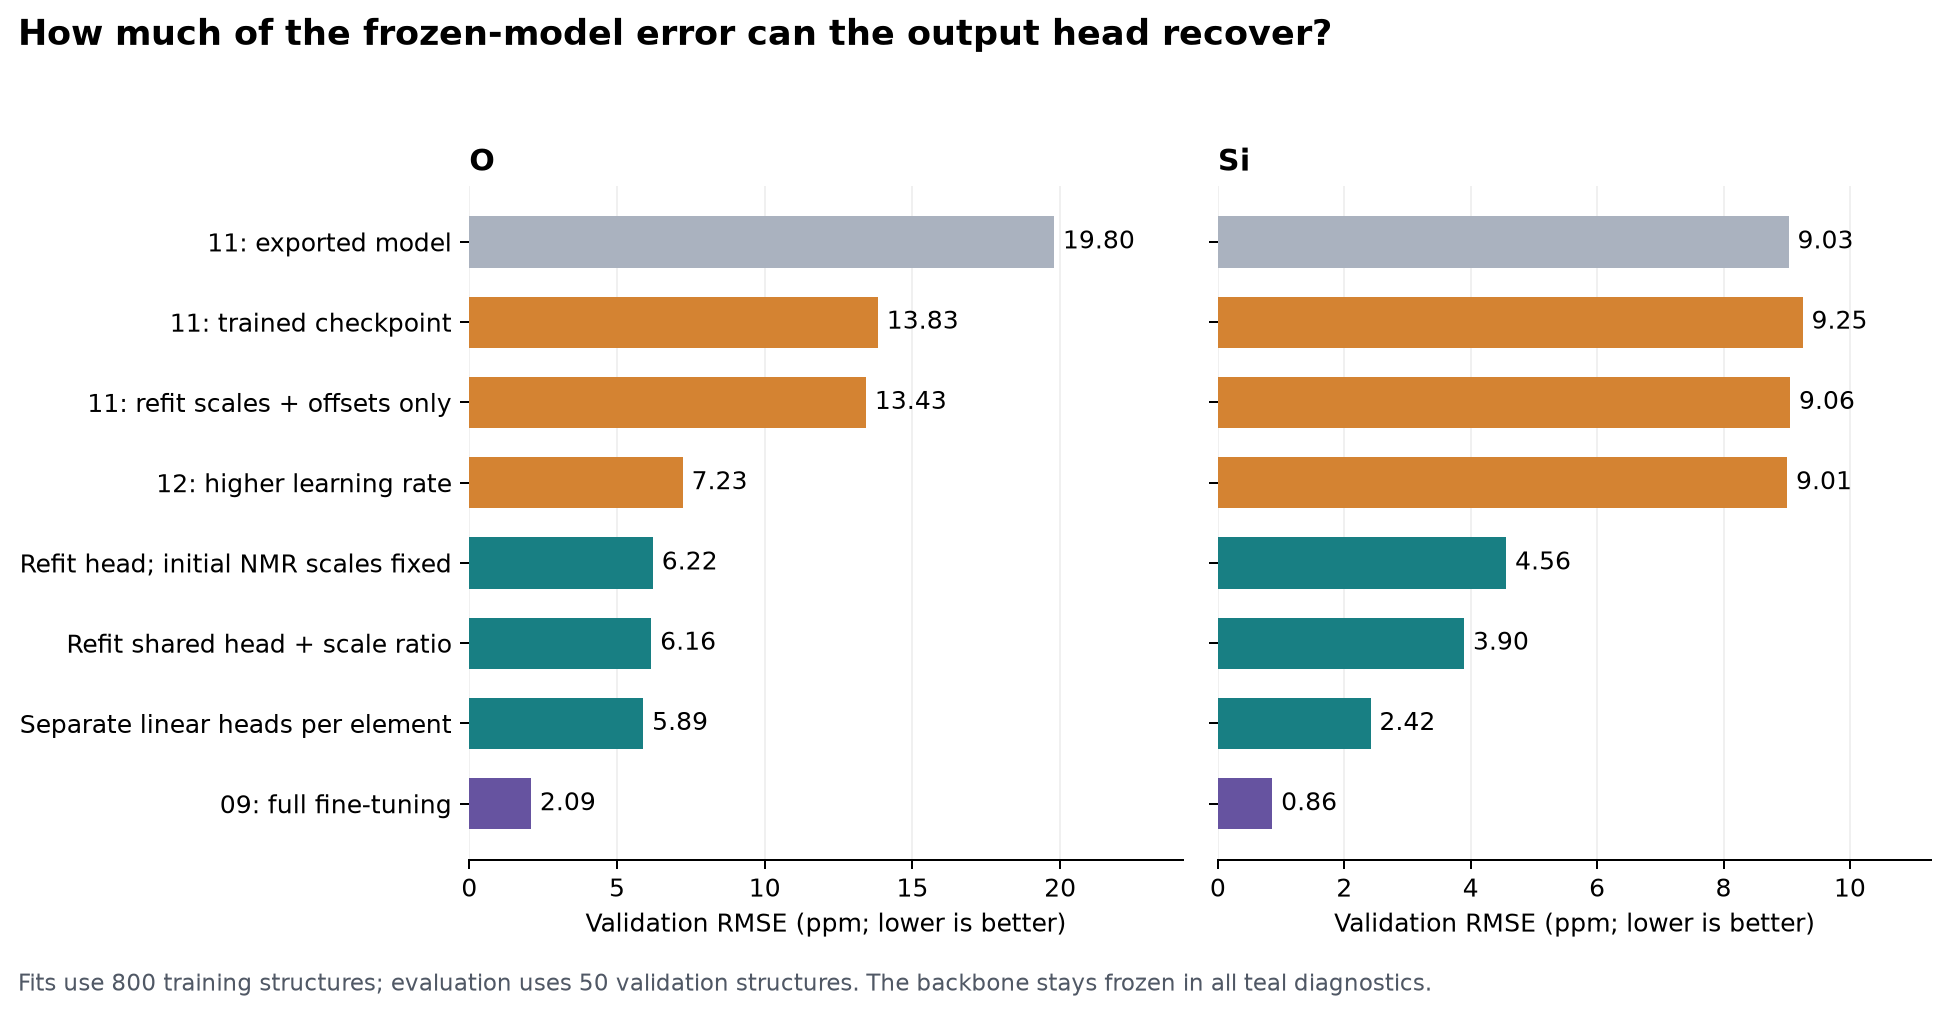

In [4]:
import os
os.environ.setdefault('MPLCONFIGDIR', '/tmp/nequip-scaler-mpl')
import matplotlib.pyplot as plt
import numpy as np
names = ['11 exported model.pt', '11 trained checkpoint',
         '11 checkpoint scales/offsets refit only', '12 trained checkpoint',
         'LS head; scales fixed to NMR std', 'LS shared head; fitted scale ratio',
         'LS separate head per element', '09 full fine-tuning']
labels = ['11: exported model', '11: trained checkpoint',
          '11: refit scales + offsets only', '12: higher learning rate',
          'Refit head; initial NMR scales fixed', 'Refit shared head + scale ratio',
          'Separate linear heads per element', '09: full fine-tuning']
colors = ['#aab2bf','#d48332','#d48332','#d48332','#187f83','#187f83','#187f83','#6653a0']
fig, axes = plt.subplots(1, 2, figsize=(11, 5.6), sharey=True)
for ax, element in zip(axes, ['O', 'Si']):
    subset = metrics.query("split == 'valid' and element == @element").set_index('model')
    values = subset.loc[names, 'RMSE'].to_numpy()
    ax.barh(np.arange(len(names)), values, color=colors, height=0.64)
    for i, value in enumerate(values): ax.text(value + max(values)*.015, i, f'{value:.2f}', va='center', fontsize=10)
    ax.set_xlim(0, max(values)*1.22)
    ax.set_title(element, loc='left', fontweight='bold')
    ax.set_xlabel('Validation RMSE (ppm; lower is better)')
    ax.grid(axis='x', alpha=.18); ax.set_axisbelow(True)
    ax.spines[['top','right','left']].set_visible(False)
axes[0].set_yticks(np.arange(len(names)), labels)
axes[0].invert_yaxis()
fig.suptitle('How much of the frozen-model error can the output head recover?', x=.02, ha='left', fontweight='bold', fontsize=14)
fig.text(.02,.015,'Fits use 800 training structures; evaluation uses 50 validation structures. The backbone stays frozen in all teal diagnostics.',fontsize=9,color='#505865')
fig.tight_layout(rect=(0,.04,1,.94))
fig.savefig(OUT / 'scaler-diagnosis.png', dpi=180, bbox_inches='tight')
fig.savefig(OUT / 'scaler-diagnosis.pdf', bbox_inches='tight')
plt.show()


## What the evidence says

- The notebook printed the wrong model's scales. Correcting that display is necessary, but cannot change any model predictions.
- The export/checkpoint discrepancy is material: all-atom validation RMSE is **16.984 ppm** for the export versus **12.495 ppm** for the trained checkpoint.
- Optimizing only experiment 11's scales and offsets gives **12.148 ppm**. This measures how much can be repaired by simple output calibration while keeping its learned readout direction.
- Directly fitting the shared head with the original NMR standard-deviation scales fixed gives **5.719 ppm**. Allowing the scale ratio to vary gives **5.512 ppm**, with Si/O ratio **-0.676717**. The latter stays within the existing head's prediction function class.
- Independent elemental linear heads reach **5.008 ppm**, compared with **1.780 ppm** for full fine-tuning. Separate heads change the architecture; the remaining gap is not proof that all useful information is absent from the features. A nonlinear head or adapting the final interaction layer could access information differently.

The scaler is not demonstrated to be a broken implementation or a missing energy-to-shielding conversion. It affects optimization and relative elemental weighting, but a scalar cannot create new environment dependence that the learned readout fails to extract. Interpret the direct-fit results jointly with the artifact mismatch and the shared-head restriction.

## Reproduce and inspect

`extract.py` caches the exact frozen 128-dimensional features and verifies frozen-state equality. `fit.py` performs the training-only head fits and reproduces existing predictions. Run both using the project's Python environment. `build_notebook.py` rebuilds this notebook and its figures from the results. `manifest.json` records source model/data SHA256 hashes. `metrics.csv`, `scales.csv`, `diagnostics.json` and `scale-ratio-profile.csv` contain the numerical evidence.

Relevant implementation locations in `/Users/louismcauliffe/code/research/NequIP_experiments`:

- `nmr_helpers/shielding_transfer.py:41`: copy/freeze list excludes readout, scales and offsets.
- `nmr_helpers/extract_ms_isotropy.py:51`: custom scalar-target pre-fit; means and standard deviations from training labels.
- `.venv/lib/python3.11/site-packages/graph_pes/models/components/scaling.py:36` and `:103`: energy and tensor scalers both multiply local predictions by the element-indexed parameter.
- `.venv/lib/python3.11/site-packages/graph_pes/models/e3nn/nequip.py:511` and `:544`: direct linear readout, then output scaling.
- `.venv/lib/python3.11/site-packages/graph_pes/models/addition.py:177`: addition of offset and scaled model output.
- `.venv/lib/python3.11/site-packages/graph_pes/training/callbacks.py:234`: exporter lacks a sanity-check guard.
